<a href="https://colab.research.google.com/github/Ziad-Gebril/Linear-Models-and-Support-Vector-Machines/blob/Part-C-Logistic-REG/ML_assignment_2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **IMPORTS**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split



# **Part A**

In [2]:
from sklearn.datasets import load_diabetes, load_breast_cancer, load_digits,load_iris

diabetes = load_diabetes(scaled = False)
XD = diabetes.data
YD = diabetes.target

cancer = load_breast_cancer()
XC = cancer.data
YC = 1 - cancer.target    # flipping the data

digits = load_digits()
XDG = digits.data / 16  # dividing the digits data by 16
YDG = digits.target

iris = load_iris()
XI = iris.data
YI = iris.target

In [3]:
XD_tr, XD_te, yD_tr, yD_te = train_test_split(XD, YD, test_size=0.2, random_state=42)
XD_tr, XD_va, yD_tr, yD_va = train_test_split(XD_tr, yD_tr, test_size=0.25, random_state=42)

XC_tr, XC_te, yC_tr, yC_te = train_test_split(XC, YC, test_size=0.2, random_state=42, stratify=YC)
XC_tr, XC_va, yC_tr, yC_va = train_test_split(XC_tr, yC_tr, test_size=0.25, random_state=42, stratify=yC_tr)

XDG_tr, XDG_te, yDG_tr, yDG_te = train_test_split(XDG, YDG, test_size=0.2, random_state=42, stratify=YDG)
XDG_tr, XDG_va, yDG_tr, yDG_va = train_test_split(XDG_tr, yDG_tr, test_size=0.25, random_state=42, stratify=yDG_tr)

XI_tr, XI_te, yI_tr, yI_te = train_test_split(XI, YI, test_size=0.2, random_state=42, stratify=YI)
XI_tr, XI_va, yI_tr, yI_va = train_test_split(XI_tr, yI_tr, test_size=0.25, random_state=42, stratify=yI_tr)

In [4]:
for name, y_tr, y_va, y_te in [
    ("Cancer", yC_tr, yC_va, yC_te),
    ("Digits", yDG_tr, yDG_va, yDG_te),
    ("Iris", yI_tr, yI_va, yI_te)
]:
    print(f"\n{name}")
    print("Train:", np.unique(y_tr, return_counts=True))
    print("Validation:", np.unique(y_va, return_counts=True))
    print("Test:", np.unique(y_te, return_counts=True))


Cancer
Train: (array([0, 1]), array([214, 127]))
Validation: (array([0, 1]), array([71, 43]))
Test: (array([0, 1]), array([72, 42]))

Digits
Train: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([106, 109, 107, 109, 109, 109, 109, 107, 104, 108]))
Validation: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 37, 35, 37, 36, 36, 36, 36, 35, 36]))
Test: (array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9]), array([36, 36, 35, 37, 36, 37, 36, 36, 35, 36]))

Iris
Train: (array([0, 1, 2]), array([30, 30, 30]))
Validation: (array([0, 1, 2]), array([10, 10, 10]))
Test: (array([0, 1, 2]), array([10, 10, 10]))


In [5]:
print("Diabetes:", len(yD_tr), len(yD_va), len(yD_te))
print("Cancer:", len(yC_tr), len(yC_va), len(yC_te))
print("Digits:", len(yDG_tr), len(yDG_va), len(yDG_te))
print("Iris:", len(yI_tr), len(yI_va), len(yI_te))

Diabetes: 264 89 89
Cancer: 341 114 114
Digits: 1077 360 360
Iris: 90 30 30


In [6]:
class S:
    pass

def Standardizer_fit(SS,X):
  SS.mean = np.mean(X,axis = 0)
  SS.std = np.std(X,axis = 0)


  n=len(SS.std)
  i=0
  while(i<n):
    if (SS.std[i]==0):
      SS.std[i] = 1
    i+=1

  return SS


def transform(SS, X):
      return (X - SS.mean) / SS.std   # z= (x-m)/o'


def add_bias(XX):
  one = np.ones((len(XX),1))
  X = np.column_stack((one,XX))
  return X

In [7]:
# made the test with Ai
# Diabetes
scaler_D = S()
Standardizer_fit(scaler_D, XD_tr)

XD_tr = transform(scaler_D, XD_tr)
XD_va = transform(scaler_D, XD_va)
XD_te = transform(scaler_D, XD_te)


# Cancer
scaler_C = S()
Standardizer_fit(scaler_C, XC_tr)

XC_tr = transform(scaler_C, XC_tr)
XC_va = transform(scaler_C, XC_va)
XC_te = transform(scaler_C, XC_te)


# Iris
scaler_I = S()
Standardizer_fit(scaler_I, XI_tr)

XI_tr = transform(scaler_I, XI_tr)
XI_va = transform(scaler_I, XI_va)
XI_te = transform(scaler_I, XI_te)


for name, X_tr, X_va, X_te in [
    ("Diabetes", XD_tr, XD_va, XD_te),
    ("Cancer", XC_tr, XC_va, XC_te),
    ("Iris", XI_tr, XI_va, XI_te)
]:
    print(f"\n{name}")
    print("Train mean:", np.round(X_tr.mean(axis=0), 6))
    print("Train std:", np.round(X_tr.std(axis=0), 6))


Diabetes
Train mean: [-0.  0. -0. -0. -0. -0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]

Cancer
Train mean: [ 0.  0. -0.  0. -0. -0.  0. -0.  0. -0.  0.  0. -0. -0. -0.  0. -0. -0.
  0. -0. -0.  0. -0. -0. -0.  0.  0. -0.  0. -0.]
Train std: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]

Iris
Train mean: [-0.  0. -0.  0.]
Train std: [1. 1. 1. 1.]


In [8]:
def mse(y_t, y_p):
  errors = y_t - y_p
  return np.mean(np.array(errors) ** 2)


def rmse(y_t, y_p):
  return np.sqrt(mse(y_t, y_p))


def r2(y_t, y_p):
  s1= np.sum((y_t-y_p)**2) # comparing each one to the predicted one
  s2 = np.sum(( np.mean(y_t)-y_t)**2) # comparing each one to the mean of all of them
  return 1-(s1/s2)


def accuracy(y_t, pred):
  T= np.sum(y_t == pred)
  total = len(y_t)
  return T/total

#def conf_matrix(y, pred):
 # classesT =np.unique(y)
  #CM = np.zeros((K,K))
##
 # classesP =np.unique(y)
 #
  #i=0
#
 # while(i<K):
  #  TR = np.where(classesT == y[i])[0][0]
   # PR = np.where(classesP == pred[i])[0][0]
    #CM[TR][PR] += 1
#
 #   i+=1
#
 # return CM\\

def confusion_matrix(y, pred, K):
    CM = np.bincount(
        K * y + pred,
        minlength=K * K
    ).reshape(K, K)

    return CM

In [9]:
def precision(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  PR = np.zeros(n)

  while(i<n):
    if np.sum(CM[:, i]) == 0:
      PR[i] = 0
      # Precision = 0 for a class that is never predicted
    else:
      PR[i] = d[i]/np.sum(CM[:, i]) # to take only one column
    i+=1
  return PR

def recall(CM):
  d = np.diag(CM)

  n=len(d)
  i=0
  RC = np.zeros(n)

  while(i<n):
    if np.sum(CM[i, :]) == 0:
      RC[i] = 0
      # recall = 0 for a class that is never Existed
    else:
      RC[i] = d[i]/np.sum(CM[i, :]) # to take only one row
    i+=1
  return RC


def F1(CM):
  P = precision(CM)
  R = recall(CM)

  n=len(P)
  i=0
  F = np.zeros(n)

  while(i<n):
    NOM = P[i]*R[i]
    DNOM = P[i]+R[i]
    if DNOM == 0:
      F[i] = 0
    else:
      F[i]= 2*NOM/DNOM
    i+=1
  return F

In [10]:
y_t = np.array([0, 1, 2, 0, 1])
y_p = np.array([0, 1, 0, 2, 1])

classes =np.unique(y_t)
n = len(classes)

CM = confusion_matrix(y_t, y_p, n)

macro_precision = np.mean(precision(CM))
macro_recall = np.mean(recall(CM))
macro_F1 = np.mean(F1(CM))


print("Precision:", precision(CM))
print("Macro Precision:", macro_precision)

print("Recall:", recall(CM))
print("Macro Recall:", macro_recall)

print("F1:", F1(CM))
print("Macro F1:", macro_F1)

Precision: [0.5 1.  0. ]
Macro Precision: 0.5
Recall: [0.5 1.  0. ]
Macro Recall: 0.5
F1: [0.5 1.  0. ]
Macro F1: 0.5


In [11]:
print(CM)
print(precision(CM))
print(F1(CM))

[[1 0 1]
 [0 2 0]
 [1 0 0]]
[0.5 1.  0. ]
[0.5 1.  0. ]


In [12]:
from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    confusion_matrix as sk_confusion_matrix,
    precision_recall_fscore_support
)

rng = np.random.default_rng(42)

N = 500
K = 4

# Regression
y_reg = rng.normal(size=N)
pred_reg = rng.normal(size=N)

# Classification
y = rng.integers(0, K, size=N)
pred = rng.integers(0, K, size=N)

In [13]:
np.testing.assert_allclose(
    mse(y_reg, pred_reg),
    mean_squared_error(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    rmse(y_reg, pred_reg),
    np.sqrt(mean_squared_error(y_reg, pred_reg)),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    r2(y_reg, pred_reg),
    r2_score(y_reg, pred_reg),
    atol=1e-12, rtol=0
)

print("Regression metrics: PASSED")

Regression metrics: PASSED


In [14]:
CM = confusion_matrix(y, pred, K)

CM_ref = sk_confusion_matrix(
    y, pred,
    labels=np.arange(K)
)

np.testing.assert_array_equal(CM, CM_ref)

print("Confusion matrix: PASSED")

Confusion matrix: PASSED


In [15]:
P_ref, R_ref, F_ref, _ = precision_recall_fscore_support(
    y, pred,
    labels=np.arange(K),
    average=None,
    zero_division=0
)

np.testing.assert_allclose(
    accuracy(y, pred),
    accuracy_score(y, pred),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    precision(CM), P_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    recall(CM), R_ref,
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    F1(CM), F_ref,
    atol=1e-12, rtol=0
)

print("Classification metrics: PASSED")

Classification metrics: PASSED


In [16]:
np.testing.assert_allclose(
    np.mean(precision(CM)),
    np.mean(P_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(recall(CM)),
    np.mean(R_ref),
    atol=1e-12, rtol=0
)

np.testing.assert_allclose(
    np.mean(F1(CM)),
    np.mean(F_ref),
    atol=1e-12, rtol=0
)

print("Macro averages: PASSED")

Macro averages: PASSED


In [17]:
def grad_check(f, grad, w, eps=1e-5):
    w = np.array(w, dtype=float)

    g_analytic = grad(w).flatten()
    g_numeric = np.zeros(w.size)

    # Select entries to check
    rng = np.random.default_rng(42)

    if w.size > 100:
        indices = rng.choice(w.size, size=100, replace=False)
    else:
        indices = np.arange(w.size)

    # Central differences
    for i in indices:
        w_plus = w.copy()
        w_minus = w.copy()

        w_plus.flat[i] += eps
        w_minus.flat[i] -= eps

        g_numeric[i] = (f(w_plus) - f(w_minus)) / (2 * eps)

    # Compare only the selected entries
    g_a = g_analytic[indices]
    g_n = g_numeric[indices]

    numerator = np.linalg.norm(g_a - g_n)
    denominator = max(
        np.linalg.norm(g_a),
        np.linalg.norm(g_n),
        1e-12
    )

    return numerator / denominator

In [18]:
# a test fro grad from the AI

def test_f(w):
    return np.sum(w**2)

def test_grad(w):
    return 2*w

rng = np.random.default_rng(42)
w = rng.normal(0, 0.1, size=5)

error = grad_check(test_f, test_grad, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1752888136783617e-12
Passed: True


# **Part C**

**Logistic** **REG**

In [82]:

def Naive_sigmoid(z):
  return 1/(1+np.exp(-z))

def Naive_loss(y,z):
  return np.log(1 + np.exp(z)) - y*z

In [76]:
def getZ(W,X):
  return X@W

def sigmoid(z):
  return np.exp(-np.logaddexp(0, -z))

def loss(z,y):
  return np.logaddexp(0, z) - y*z

In [68]:
def logistic_loss(x,y,w,L):

  z = getZ(w,x)

  n = len(z)
  LS = loss(z, y)

  return (1/n) * np.sum(LS) + (L/2) * np.sum(w[1:]**2)

In [72]:
X = add_bias(XC_tr)
y = yC_tr

w = np.zeros(X.shape[1])
L = 0.1

print(logistic_loss(X,y,w,L))

0.6931471805599453


In [83]:
z = np.array([-800.0, 800.0])
y = np.array([0.0, 1.0])

print("Sigmoid:", sigmoid(z))
print("Loss:", loss(z, y))
print()
print("Naive_Sigmoid:", Naive_sigmoid(z))
print("Naive_Loss:", Naive_loss(z, y))

Sigmoid: [0. 1.]
Loss: [0. 0.]

Naive_Sigmoid: [0. 1.]
Naive_Loss: [ 6.93147181e-01 -7.98686738e+02]


/tmp/ipykernel_501/3486945463.py:2: RuntimeWarning: overflow encountered in exp
  return 1/(1+np.exp(-z))


In [80]:
def logistic_gradient(x, y, w, L):
    z = getZ(w, x)
    p = sigmoid(z)
    n = len(y)

    grad = (x.T @ (p-y)) / n

    reg = w.copy()
    reg[0] = 0

    grad += L * reg

    return grad


X = add_bias(XC_tr)
y = yC_tr
w = np.zeros(X.shape[1])
L = 0.1

grad = logistic_gradient(X, y, w, L)

print("Gradient shape:", grad.shape)
print("Gradient:", grad)

Gradient shape: (31,)
Gradient: [ 0.12756598 -0.35615821 -0.20851311 -0.36150822 -0.34543143 -0.1732737
 -0.2929318  -0.33836193 -0.37797716 -0.18012204  0.01353701 -0.28003774
  0.00255715 -0.27706347 -0.27019289  0.02294408 -0.14732071 -0.13332
 -0.21278687 -0.01550583 -0.04519853 -0.37574099 -0.23467772 -0.37881437
 -0.3529114  -0.19457899 -0.28493273 -0.30768966 -0.38352891 -0.21285873
 -0.15231311]


In [81]:
f = lambda w: logistic_loss(X, y, w, 0.1)
g = lambda w: logistic_gradient(X, y, w, 0.1)

error = grad_check(f, g, w)

print("Relative error:", error)
print("Passed:", error < 1e-6)

Relative error: 1.1738296628658992e-11
Passed: True


**Training and regularization**

In [84]:
X_train = add_bias(XC_tr)
X_validation = add_bias(XC_va)
X_testing = add_bias(XC_te)

y_train = yC_tr
y_validation = yC_va
y_testing = yC_te

In [138]:
def logistic_accuracy(x, y, w):
    z = getZ(w, x)
    p = sigmoid(z)
    y_pred = (p >= 0.5).astype(int) #got it from ai better than the loop

    return accuracy(y, y_pred)

def train_logistic(X_train, y_train, X_val, y_val, L, eta=0.5, epochs=3000):
    weights_history = []
    w = np.zeros(X_train.shape[1])

    train_losses = []
    val_losses = []
    train_accuracies = []
    val_accuracies = []

    for epoch in range(epochs):

        grad = logistic_gradient(X_train, y_train, w, L)

        w = w - eta * grad
        weights_history.append(w.copy())


        train_losses.append(logistic_loss(X_train, y_train, w, L))
        val_losses.append(logistic_loss(X_val, y_val, w, L))

        train_accuracies.append(logistic_accuracy(X_train, y_train, w))
        val_accuracies.append(logistic_accuracy(X_val, y_val, w))

    return w, train_losses, val_losses, train_accuracies, val_accuracies,weights_history



In [140]:
λ = [0, 1e-3, 1e-2, 1e-1, 1]

for i in range(0,len(λ)):
  w, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,L=λ[i])

  print(f"Final training loss for L = {λ[i]}: {tr_loss[-1]}")
  print(f"Final validation loss for L = {λ[i]}: {va_loss[-1]}")
  print(f"Final training accuracy for L = {λ[i]}: {tr_acc[-1]}")
  print(f"Final validation accuracy for L = {λ[i]}: {va_acc[-1]}")
  print(f"Lambda = {λ[i]}, ||w|| = {np.linalg.norm(w[1:]):.4f}")
  print()

  results[i] = {
        "λ": λ[i],
        "train_loss": tr_loss[-1],
        "val_loss": va_loss[-1],
        "train_acc": tr_acc[-1],
        "val_acc": va_acc[-1],
        "weight_norm": np.linalg.norm(w[1:])
    }


Final training loss for L = 0: 0.029614950111845537
Final validation loss for L = 0: 0.08419249601904281
Final training accuracy for L = 0: 0.9941348973607038
Final validation accuracy for L = 0: 0.9736842105263158
Lambda = 0, ||w|| = 8.1322

Final training loss for L = 0.001: 0.054254042278429615
Final validation loss for L = 0.001: 0.08620739680111854
Final training accuracy for L = 0.001: 0.9882697947214076
Final validation accuracy for L = 0.001: 0.9736842105263158
Lambda = 0.001, ||w|| = 5.0999

Final training loss for L = 0.01: 0.09811173825907171
Final validation loss for L = 0.01: 0.11000996461449455
Final training accuracy for L = 0.01: 0.9853372434017595
Final validation accuracy for L = 0.01: 0.9736842105263158
Lambda = 0.01, ||w|| = 2.3257

Final training loss for L = 0.1: 0.19565854198534002
Final validation loss for L = 0.1: 0.20266500651013983
Final training accuracy for L = 0.1: 0.9736070381231672
Final validation accuracy for L = 0.1: 0.9736842105263158
Lambda = 0.1, |

In [142]:
best_L = 0 # as it has the lowest validation loss

w_best, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,L=best_L)

test_acc = logistic_accuracy(X_testing, y_testing, w_best)

print("Best lambda:", best_L)
print("Test accuracy:", test_acc)

Best lambda: 0
Test accuracy: 0.9736842105263158


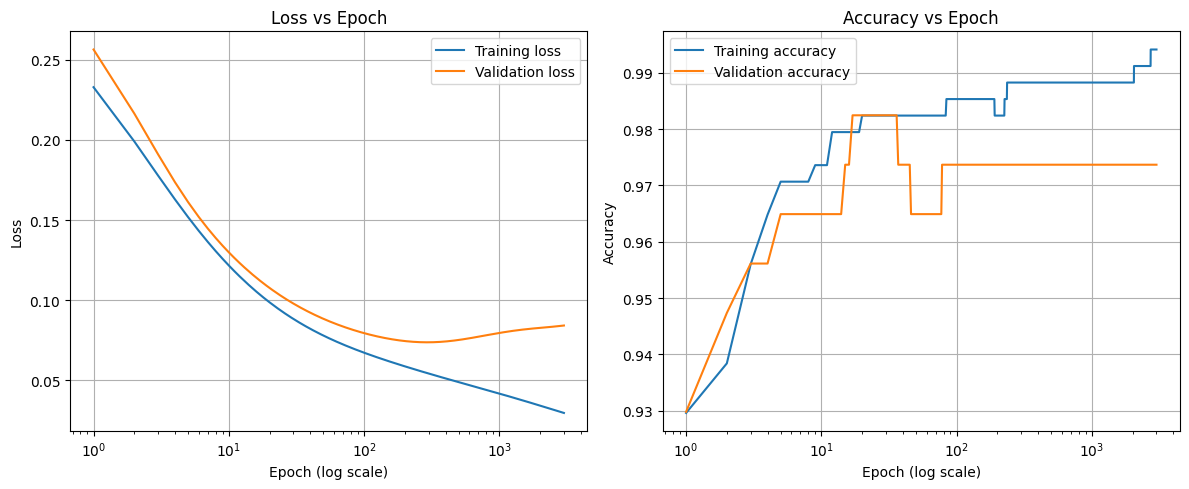

In [127]:
# Ai help in plotting

epochs = np.arange(1, 3001)

plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(epochs, tr_loss, label="Training loss")
plt.plot(epochs, va_loss, label="Validation loss")
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Loss")
plt.title("Loss vs Epoch")
plt.legend()
plt.grid(True)

# Accuracy
plt.subplot(1, 2, 2)
plt.plot(epochs, tr_acc, label="Training accuracy")
plt.plot(epochs, va_acc, label="Validation accuracy")
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs Epoch")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

In [143]:


η = [0.01, 0.1, 1, 5, 20]

for i in range(0,len(η)):
  w, tr_loss, va_loss, tr_acc, va_acc ,weights_history = train_logistic(X_train, y_train,X_validation, y_validation,0.01,η[i],1000)

  print(f"Final training loss for η = {η[i]}: {tr_loss[-1]}")
  print(f"Final validation loss for η = {η[i]}: {va_loss[-1]}")
  print(f"Final training accuracy for η = {η[i]}: {tr_acc[-1]}")
  print(f"Final validation accuracy for η = {η[i]}: {va_acc[-1]}")
  print(f"η = {η[i]}, ||w|| = {np.linalg.norm(w[1:]):.4f}")
  print()


  results[i] = {
        "η": η[i],
        "train_loss": tr_loss[-1],
        "val_loss": va_loss[-1],
        "train_acc": tr_acc[-1],
        "val_acc": va_acc[-1],
        "weight_norm": np.linalg.norm(w[1:])
    }


Final training loss for η = 0.01: 0.11628901770966023
Final validation loss for η = 0.01: 0.125355573218424
Final training accuracy for η = 0.01: 0.9794721407624634
Final validation accuracy for η = 0.01: 0.9736842105263158
η = 0.01, ||w|| = 1.4877

Final training loss for η = 0.1: 0.09831148320292545
Final validation loss for η = 0.1: 0.11041120022918247
Final training accuracy for η = 0.1: 0.9824046920821115
Final validation accuracy for η = 0.1: 0.9649122807017544
η = 0.1, ||w|| = 2.2540

Final training loss for η = 1: 0.09811173825937314
Final validation loss for η = 1: 0.11000997486319236
Final training accuracy for η = 1: 0.9853372434017595
Final validation accuracy for η = 1: 0.9736842105263158
η = 1, ||w|| = 2.3257

Final training loss for η = 5: 0.09811173825907171
Final validation loss for η = 5: 0.11000996459546292
Final training accuracy for η = 5: 0.9853372434017595
Final validation accuracy for η = 5: 0.9736842105263158
η = 5, ||w|| = 2.3257

Final training loss for η = 2

**TRAINING**

In [155]:
w, tr_loss, va_loss, tr_acc, va_acc, weights_history = train_logistic(X_train, y_train,X_validation, y_validation,0,0.5,20000)

epochs = np.arange(1, 20001)
W = np.array(weights_history)
weight_norms = np.linalg.norm(W[:, 1:], axis=1)

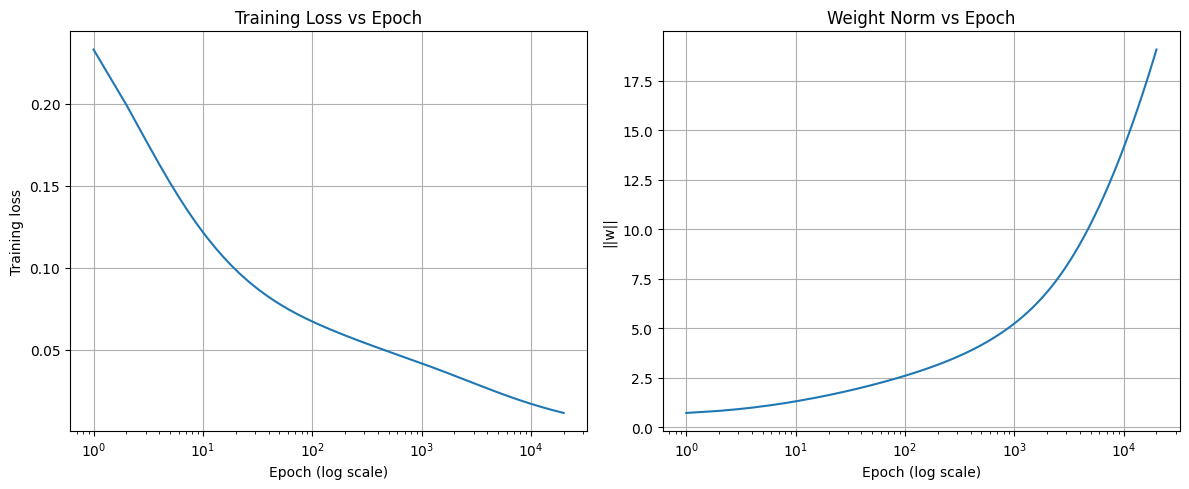

In [154]:
plt.figure(figsize=(12, 5))

# Training loss
plt.subplot(1, 2, 1)
plt.plot(epochs, tr_loss)
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("Training loss")
plt.title("Training Loss vs Epoch")
plt.grid(True)

# Weight norm
plt.subplot(1, 2, 2)
plt.plot(epochs, weight_norms)
plt.xscale("log")
plt.xlabel("Epoch (log scale)")
plt.ylabel("||w||")
plt.title("Weight Norm vs Epoch")
plt.grid(True)

plt.tight_layout()
plt.show()


as training loss decreases continuously and Weight norm increases continuously this indicates that the data is linearlly seperable.

multiplying the weight vector by an increasingly large positive constant preserves the classification decisions while increasing the margins and reducing the logistic loss toward zero. However, the loss never reaches exactly zero for any finite weight vector. Therefore, the unregularized logistic regression objective has an infimum but no finite minimizer.

L2 regularization adds a penalty to the squared weights for large weights, creating a balance between minimizing classification loss and keeping the weights small.